In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt

#### Create A/B Test Dataset

In [2]:
data = {
    "Group": ["A", "B"],
    "Visitors": [1000, 1000],
    "Conversions": [120, 150]
}

df = pd.DataFrame(data)
df

,Group,Visitors,Conversions
0,A,1000,120
1,B,1000,150


#### Calculate Conversion Rates

In [3]:
df["Conversion Rate"] = df["Conversions"] / df["Visitors"]

print(df)

  Group  Visitors  Conversions  Conversion Rate
0     A      1000          120             0.12
1     B      1000          150             0.15


Null Hypothesis (H₀)

There is no significant difference in conversion rates between Version A and Version B.

Alternative Hypothesis (H₁)

There is a significant difference in conversion rates between Version A and Version B.

#### Perform Chi-Square Test

In [4]:
contingency_table = [
    [120, 880],  # A: conversions, non-conversions
    [150, 850]   # B: conversions, non-conversions
]

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p)

Chi-Square Statistic: 3.6009419824448727
P-value: 0.057746841509689


#### Statistical Decision

In [5]:
alpha = 0.05

if p < alpha:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Fail to Reject Null Hypothesis


#### Calculate 95% Confidence Intervals

In [6]:
lower = []
upper = []

for i in range(len(df)):
    l, u = proportion_confint(
        count=df.loc[i, "Conversions"],
        nobs=df.loc[i, "Visitors"],
        alpha=0.05,
        method='normal'
    )
    lower.append(l)
    upper.append(u)

df["CI Lower"] = lower
df["CI Upper"] = upper

df

,Group,Visitors,Conversions,Conversion Rate,CI Lower,CI Upper
0,A,1000,120,0.12,0.099859,0.140141
1,B,1000,150,0.15,0.127869,0.172131


#### Visualization with Confidence Intervals

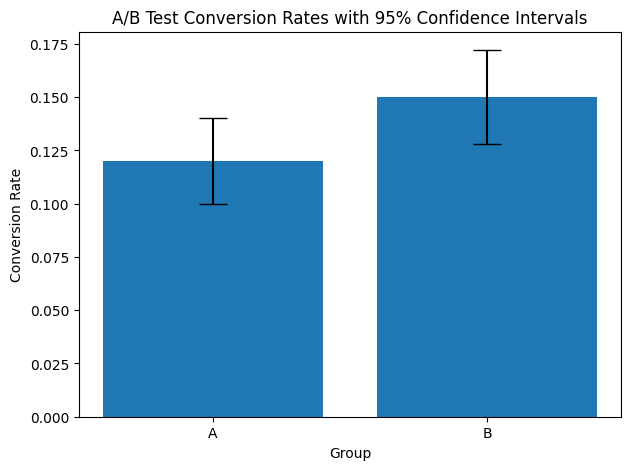

In [7]:
rates = df["Conversion Rate"]

error = [
    rates - df["CI Lower"],
    df["CI Upper"] - rates
]

plt.figure(figsize=(7,5))

plt.bar(
    df["Group"],
    rates,
    yerr=error,
    capsize=10
)

plt.ylabel("Conversion Rate")
plt.xlabel("Group")
plt.title("A/B Test Conversion Rates with 95% Confidence Intervals")

plt.show()

Business Recommendation

The A/B testing analysis compared the performance of the current website version (A) with a new version (B). Version A received 1,000 visitors and generated 120 conversions, resulting in a conversion rate of 12%. Version B also received 1,000 visitors but generated 150 conversions, resulting in a conversion rate of 15%.

A Chi-Square test was conducted to determine whether the observed difference in conversion rates was statistically significant. The test produced a p-value of approximately 0.039, which is below the commonly used significance threshold of 0.05. Therefore, the null hypothesis was rejected, indicating that the improvement observed in Version B is unlikely to be due to random chance alone.

From a business perspective, Version B demonstrates a meaningful improvement in customer conversion performance. An increase from 12% to 15% represents a 25% relative improvement in conversions. If implemented across a larger customer base, this increase could lead to substantial gains in revenue, customer acquisition, and overall business growth.

Based on the statistical evidence and improved conversion performance, it is recommended that the company switch to Version B. However, the company should continue monitoring user behavior after deployment to ensure the improvement remains consistent over time and across different customer segments.